# Housing effort in Australia and New Zealand: investigation notebook

Companion to the *Housing Effort Down Under* write-up, which re-runs the method of [The Housing Market is NUTS](https://nuts.logical.li/) for Australia and NZ.

**Effort** = median dwelling price ÷ median (or average) annual earnings, i.e. years of wage per dwelling. Neither country publishes price per m², so this is not the original's months-per-m² metric.

Sections:
1. Load the 2023 cross-section (50 AU labour-market regions, 57 NZ districts with metros merged)
2. Density vs effort fits, with the original's IQR outlier rule
3. Why NZ differs: price and wage elasticities, population growth
4. Mortgage simulator (change the assumptions)
5. Time series, 1986–2025: capitals, metros, national OECD ratios
6. Has the density relationship changed over time?
7. Maps
8. Where is housing dearer than density predicts?
9. The bid-rent curve: effort vs distance from the CBD
10. Have NZ districts converged? (and the Auckland halo)
11. Repayment burden with historical interest rates (AU)
12. Open questions

Rebuild everything from `raw/` with the scripts in `scripts/` (see the last cell).

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, math
ROOT = Path.cwd() if (Path.cwd()/'data').exists() else Path('/Volumes/T7/vibe/economics/housing-policy-research/au-nz-density')
DATA, TS, RAW = ROOT/'data', ROOT/'data'/'timeseries', ROOT/'raw'
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .3})
AU, NZ = '#2a78d6', '#eb6834'
au = pd.read_csv(DATA/'au_labour_market_regions.csv', index_col=0)
nz = pd.read_csv(DATA/'nz_labour_market_regions.csv', index_col=0).dropna(subset=['eff'])
print(len(au), 'AU regions;', len(nz), 'NZ districts')
au[['eff','eff_unit','dens','accfood','price','wage','workers_pow_2021','capital']].sort_values('eff', ascending=False).head(10).round(2)

50 AU regions; 57 NZ districts


,eff,eff_unit,dens,accfood,price,wage,workers_pow_2021,capital
name,,,,,,,,
Richmond - Tweed,16.69,13.93,9.68,14.28,832640.90,49880.0,99420,False
Southern Highlands and Shoalhaven,16.56,12.27,8.99,13.52,897383.26,54200.0,60308,False
Sunshine Coast,15.93,12.59,51.58,11.62,872736.10,54799.0,159186,False
Greater Sydney,15.68,11.56,192.93,9.58,1044391.16,66619.0,2386250,True
Gold Coast,14.30,11.82,150.08,12.68,798133.82,55817.0,278824,False
Illawarra,14.21,11.47,74.02,9.89,892093.34,62765.0,113940,False
Coffs Harbour - Grafton,14.07,10.75,4.16,12.61,713184.22,50693.0,54999,False
Mid North Coast,13.92,11.21,4.09,12.45,701854.76,50415.0,77135,False
Newcastle and Lake Macquarie,12.62,10.38,206.40,9.90,802675.85,63592.0,179684,False


## 2. Density vs effort
`fit_density` reproduces the original's method: OLS of effort on ln(jobs/km²), outliers are residuals beyond 1.5×IQR, then refit without them.

In [2]:
def ols(X, y):
    X = np.column_stack(list(X) + [np.ones(len(y))]); b, *_ = np.linalg.lstsq(X, y, rcond=None); yh = X @ b
    return b, 1 - ((y - yh)**2).sum() / ((y - y.mean())**2).sum(), y - yh

def iqr_outliers(res, k=1.5):
    q1, q3 = np.percentile(res, [25, 75]); i = q3 - q1; return (res < q1 - k*i) | (res > q3 + k*i)

def fit_density(df, y='eff', x='dens', tourism=None):
    d = df.dropna(subset=[y, x]); lx = np.log(d[x].values); yy = d[y].values
    b, r2, res = ols([lx], yy); out = iqr_outliers(res); bc, r2c, _ = ols([lx[~out]], yy[~out])
    r = dict(n=len(d), slope=b[0], intercept=b[1], r2=r2, r2_clean=r2c, outliers=list(d.index[out]))
    if tourism:
        t = d.dropna(subset=[tourism]); r['r2_tourism'] = ols([t[tourism].values], t[y].values)[1]
        r['r2_density_tourism'] = ols([np.log(t[x].values), t[tourism].values], t[y].values)[1]
    return r

res_au = fit_density(au, tourism='accfood'); res_nz = fit_density(nz, tourism='gn_pw')
pd.DataFrame({'Australia': res_au, 'New Zealand': res_nz}).T

,n,slope,intercept,r2,r2_clean,outliers,r2_tourism,r2_density_tourism
Australia,50,0.849752,8.401949,0.418836,0.500122,"[Coffs Harbour - Grafton, Richmond - Tweed, So...",0.371367,0.633812
New Zealand,57,0.434901,9.954865,0.038335,0.065483,[Queenstown-Lakes],0.044766,0.191833


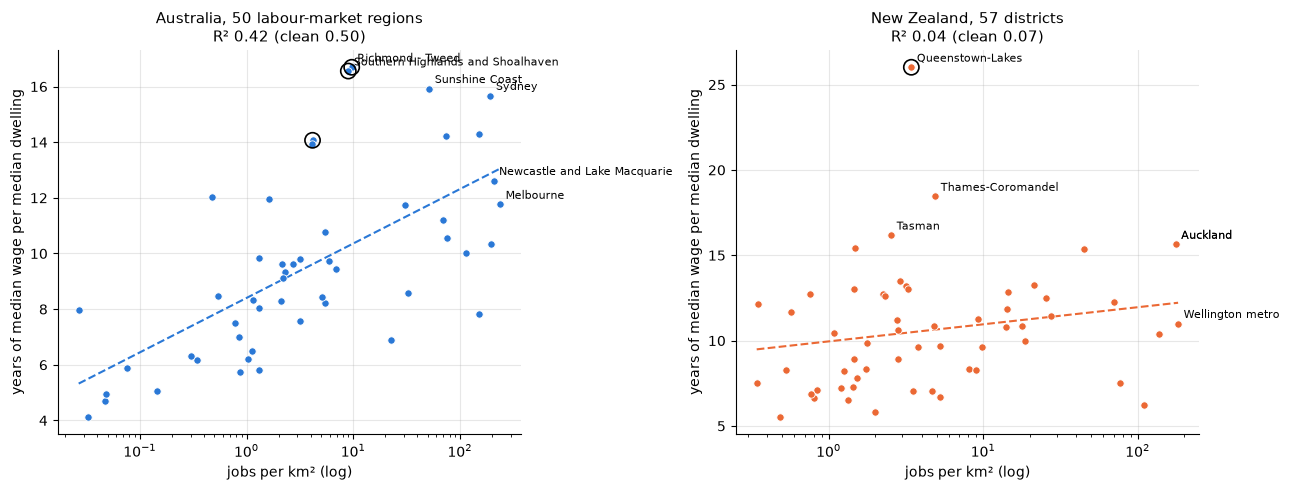

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
for ax, df, r, col, title in [(axes[0], au, res_au, AU, 'Australia, 50 labour-market regions'), (axes[1], nz, res_nz, NZ, 'New Zealand, 57 districts')]:
    ax.scatter(df.dens, df.eff, s=28, color=col, edgecolor='white', lw=.6, zorder=3)
    o = df.loc[r['outliers']]; ax.scatter(o.dens, o.eff, s=120, facecolor='none', edgecolor='k', lw=1.2, zorder=4)
    xs = np.logspace(np.log10(df.dens.min()), np.log10(df.dens.max()), 50); ax.plot(xs, r['slope']*np.log(xs) + r['intercept'], '--', color=col)
    for n in df.sort_values('eff').tail(4).index.tolist() + df.sort_values('dens').tail(2).index.tolist():
        ax.annotate(n.replace('Greater ', ''), (df.dens[n], df.eff[n]), fontsize=8, xytext=(4, 4), textcoords='offset points')
    ax.set_xscale('log'); ax.set_xlabel('jobs per km² (log)'); ax.set_ylabel('years of median wage per median dwelling')
    ax.set_title(f"{title}\nR² {r['r2']:.2f} (clean {r['r2_clean']:.2f})", fontsize=11)
plt.tight_layout()

**Try:** swap `eff` for `eff_unit` (units only) or `eff_house` (houses only) in Australia, or raise `k` in `iqr_outliers` to see how sensitive the cleaned R² is.

In [4]:
pd.DataFrame({k: fit_density(au, y=k) for k in ['eff', 'eff_unit', 'eff_house']}).T[['n','slope','r2','r2_clean','outliers']]

,n,slope,r2,r2_clean,outliers
eff,50,0.849752,0.418836,0.500122,"[Coffs Harbour - Grafton, Richmond - Tweed, So..."
eff_unit,50,0.633505,0.3794,0.429153,"[Richmond - Tweed, Southern Highlands and Shoa..."
eff_house,50,1.065778,0.483057,0.664122,"[Greater Sydney, Greater Perth, Coffs Harbour ..."


## 3. Why NZ differs
Split effort into numerator and denominator. Elasticity = change in log price (or log wage) per unit change in log density. Then test population growth as the demand measure.

In [5]:
raw_nz = pd.read_csv(RAW/'nz'/'nz_raw.csv', index_col=0).drop(index=['Chatham Islands']).dropna()
raw_nz['dens'] = raw_nz.employees / raw_nz.area_km2; raw_nz['eff'] = raw_nz.median_sale_price / raw_nz.wage
rows = {}
for name, d, p in [('Australia', au, 'price'), ('New Zealand', raw_nz, 'median_sale_price')]:
    lx = np.log(d.dens.values)
    bp, r2p, _ = ols([lx], np.log(d[p].values)); bw, r2w, _ = ols([lx], np.log(d.wage.values))
    rows[name] = {'price +% per 10x density': (10**bp[0]-1)*100, 'wage +% per 10x density': (10**bw[0]-1)*100, 'price R²': r2p, 'wage R²': r2w}
pd.DataFrame(rows).T.round(2)

,price +% per 10x density,wage +% per 10x density,price R²,wage R²
Australia,28.52,2.77,0.60,0.07
New Zealand,17.52,5.99,0.21,0.31


growth only R² 0.49; density + growth R² 0.53


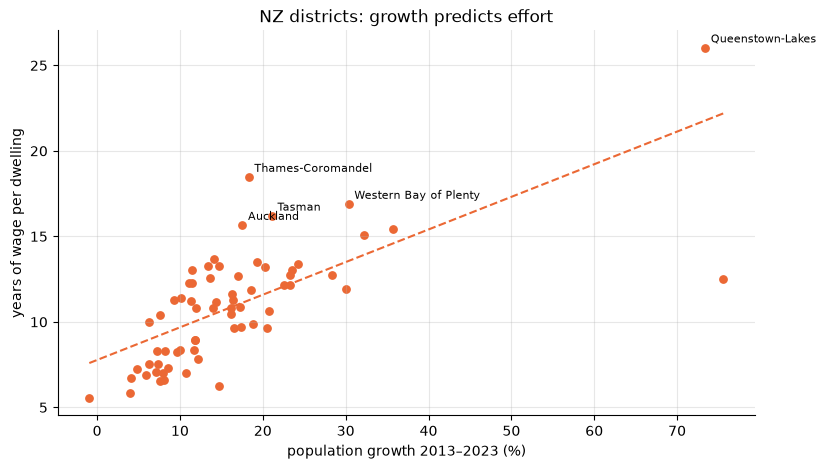

In [6]:
rear = pd.read_csv(RAW/'nz'/'rear'/'all-data.csv', dtype=str, low_memory=False)
import unicodedata, re
def norm(x):
    x = unicodedata.normalize('NFKD', str(x)).encode('ascii', 'ignore').decode(); x = re.sub(r'\s+(District|City)$', '', x).strip()
    return {'Wanganui':'Whanganui','Southland district':'Southland','Waikato district':'Waikato','Wellington city':'Wellington'}.get(x, x)
pop = rear[(rear.indicator=='population estimates') & (rear['transform']=='original')]
pop = pop.assign(ta=pop.area.map(norm), value=pop.value.astype(float), year=pop.year.astype(int)).pivot_table(index='ta', columns='year', values='value')
raw_nz['pop_growth'] = (pop[2023] / pop[2013] - 1).reindex(raw_nz.index) * 100
d = raw_nz.dropna(subset=['pop_growth'])
b, r2, _ = ols([d.pop_growth.values], d.eff.values); b2, r2b, _ = ols([np.log(d.dens.values), d.pop_growth.values], d.eff.values)
print(f'growth only R² {r2:.2f}; density + growth R² {r2b:.2f}')
ax = d.plot.scatter('pop_growth', 'eff', color=NZ, s=28); xs = np.linspace(d.pop_growth.min(), d.pop_growth.max(), 10); ax.plot(xs, b[0]*xs + b[1], '--', color=NZ)
for n in d.sort_values('eff').tail(5).index: ax.annotate(n, (d.pop_growth[n], d.eff[n]), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('population growth 2013–2023 (%)'); ax.set_ylabel('years of wage per dwelling'); ax.set_title('NZ districts: growth predicts effort');

## 4. Mortgage simulator
The original's assumptions: 90% LTV, 4% interest, 45% of net pay (net ≈ 70% of gross), one earner. `inf` = the payment never covers the interest. Change the defaults below.

In [7]:
def years_to_repay(effort, earners=1, rate=0.04, ltv=0.9, dsti=0.45, net=0.7):
    L = ltv * effort; P = dsti * net * earners / 12; r = rate / 12
    return math.inf if r * L >= P else -math.log(1 - r * L / P) / math.log(1 + r) / 12

def cliff_table(df, weight, earners=2, rate=0.04, **kw):
    d = df.copy(); d['years'] = [years_to_repay(e, earners, rate, **kw) for e in d.eff]
    w = d[weight] / d[weight].sum()
    return pd.Series({'jobs share >15y': w[d.years > 15].sum(), 'jobs share >25y': w[d.years > 25].sum(), 'jobs share never': w[np.isinf(d.years)].sum()})

out = {}
for rate in [0.03, 0.04, 0.05, 0.06, 0.07]:
    out[('AU', rate)] = cliff_table(au, 'workers_pow_2021', rate=rate); out[('NZ', rate)] = cliff_table(nz, 'employees', rate=rate)
pd.DataFrame(out).T.round(2)

,,jobs share >15y,jobs share >25y,jobs share never
AU,0.03,0.79,0.30,0.00
NZ,0.03,0.92,0.56,0.01
AU,0.04,0.83,0.53,0.00
NZ,0.04,0.95,0.72,0.02
AU,0.05,0.93,0.72,0.27
NZ,0.05,0.97,0.90,0.42
AU,0.06,0.93,0.78,0.52
NZ,0.06,0.99,0.92,0.59
AU,0.07,0.94,0.81,0.72
NZ,0.07,0.99,0.95,0.88


In [8]:
caps = ['Greater Sydney','Greater Melbourne','Greater Brisbane','Greater Perth','Greater Adelaide','Canberra (ACT)']
nzc = ['Auckland','Wellington metro','Christchurch metro','Hamilton metro','Tauranga metro','Queenstown-Lakes']
pd.DataFrame({r: pd.concat([au.loc[caps,'eff'], nz.loc[nzc,'eff']]).map(lambda e: years_to_repay(e, 2, r)) for r in [0.04, 0.05, 0.06]}).round(1).rename(columns=lambda r: f'{r:.0%}, two earners')

,"4%, two earners","5%, two earners","6%, two earners"
Greater Sydney,56.6,inf,inf
Greater Melbourne,27.9,36.8,inf
Greater Brisbane,23.1,28.0,39.1
Greater Perth,14.8,16.4,18.6
Greater Adelaide,22.3,26.8,36.2
Canberra (ACT),21.2,25.1,32.6
Auckland,56.1,inf,inf
Wellington metro,24.8,30.9,47.9
Christchurch metro,26.7,34.2,67.7
Hamilton metro,31.5,45.0,inf


## 5. Time series, 1986–2025

* **AU capitals**: ABS median established-house price (Total Value of Dwellings, 2002–2025), back-cast to 1986 with the ABS pre-2005 Price Index of Established Homes, ÷ annualised AWE (all employees, persons, total earnings) for the capital's state from 1995. Before 1995, earnings follow the OECD household disposable income index (spliced, labelled).
* **NZ metros**: HUD 12-month median sale price to December (from 1980) ÷ annualised QES average weekly earnings, all employees (from 1989). 1986–88 earnings follow the OECD income index; 1980–85 have prices only.
* These use *average earnings of all employees*, not the median employee income used in the 2023 cross-section, so levels are not identical to the snapshot.

shaded = earnings spliced on OECD income index


,1986,1995,2005,2015,2020,2025
Sydney,5.5,7.2,11.0,14.3,14.0,18.1
Melbourne,4.5,4.3,8.0,10.3,10.9,11.0
Brisbane,4.0,5.4,8.0,8.2,8.6,12.8
Adelaide,5.4,4.5,7.7,7.9,8.3,12.0
Perth,4.1,4.9,7.7,7.6,6.9,10.2
Hobart,4.1,4.1,7.0,7.1,9.5,10.4
Darwin,4.9,5.7,7.0,8.7,6.7,7.7
Canberra,5.5,5.6,7.8,8.4,9.5,11.2
Auckland,5.0,6.7,10.1,14.3,15.7,12.4
Wellington metro,4.7,5.2,8.6,8.6,13.0,10.2


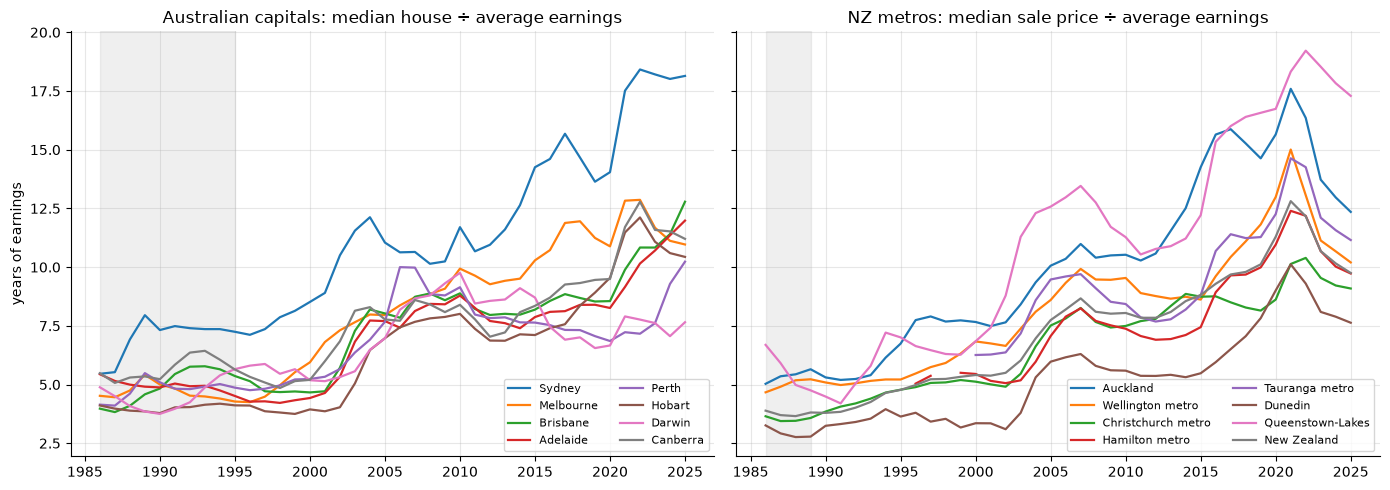

In [9]:
au_ts = pd.read_csv(TS/'au_capital_effort_1986_2025.csv', index_col=0); nz_ts = pd.read_csv(TS/'nz_metro_effort_1986_2025.csv', index_col=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
au_ts.plot(ax=axes[0], lw=1.6); axes[0].axvspan(1986, 1995, color='grey', alpha=.12); axes[0].set_title('Australian capitals: median house ÷ average earnings')
nz_ts.plot(ax=axes[1], lw=1.6); axes[1].axvspan(1986, 1989, color='grey', alpha=.12); axes[1].set_title('NZ metros: median sale price ÷ average earnings')
for a in axes: a.set_ylabel('years of earnings'); a.set_xlabel(''); a.legend(fontsize=8, ncol=2)
plt.tight_layout(); print('shaded = earnings spliced on OECD income index')
pd.concat([au_ts.loc[[1986,1995,2005,2015,2020,2025]].T, nz_ts.loc[[1986,1995,2005,2015,2020,2025]].T]).round(1)

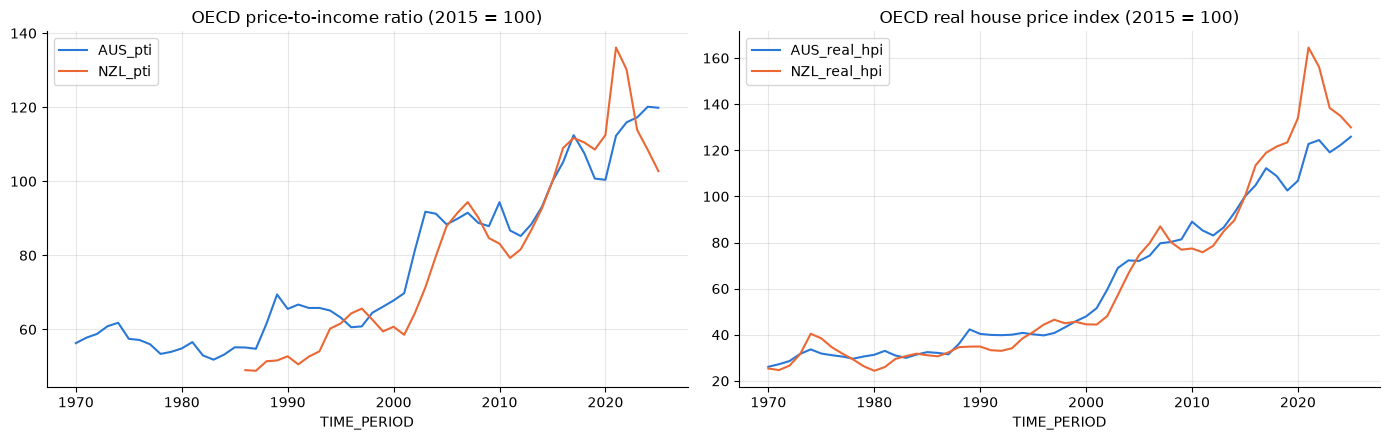

In [10]:
nat = pd.read_csv(TS/'oecd_national.csv', index_col=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
nat[['AUS_pti','NZL_pti']].plot(ax=axes[0], color=[AU, NZ]); axes[0].set_title('OECD price-to-income ratio (2015 = 100)')
nat[['AUS_real_hpi','NZL_real_hpi']].plot(ax=axes[1], color=[AU, NZ]); axes[1].set_title('OECD real house price index (2015 = 100)')
plt.tight_layout()

### Capital premium
Is the gap between the main city and the rest of the country widening? AU: capital median ÷ rest-of-state median (ABS). NZ: Auckland ÷ national median (HUD).

,NSW,Vic,Qld,SA,WA,Tas,Auckland/NZ
2005,1.76,1.52,1.12,1.43,1.29,1.35,1.30
2010,1.77,1.76,1.17,1.46,1.30,1.33,1.31
2015,2.15,1.90,1.14,1.61,1.49,1.38,1.62
2017,2.14,2.11,1.17,1.65,1.51,1.46,1.64
2020,1.89,1.79,1.25,1.70,1.41,1.53,1.39
2022,1.89,1.54,1.44,1.90,1.48,1.42,1.34
2025,1.94,1.45,1.35,1.69,1.53,1.27,1.27


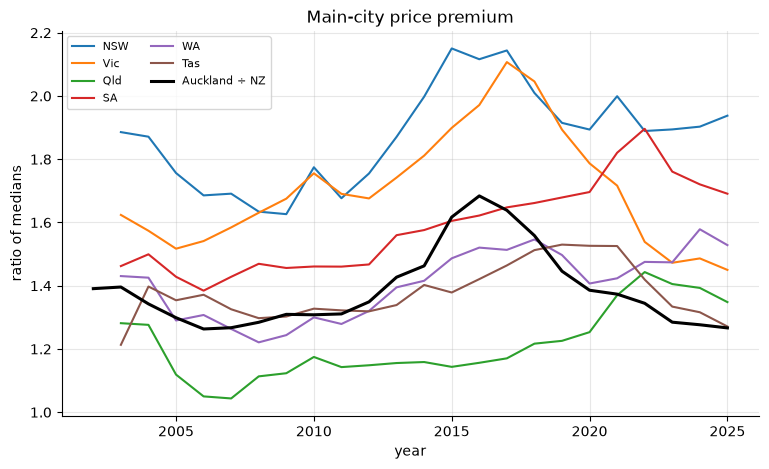

In [11]:
prem = pd.read_csv(TS/'au_capital_vs_rest_price_ratio.csv', index_col=0); akl = pd.read_csv(TS/'nz_auckland_price_premium.csv', index_col=0).iloc[:, 0]
ax = prem.plot(lw=1.5); akl.loc[2002:].plot(ax=ax, color='k', lw=2.2, label='Auckland ÷ NZ'); ax.legend(fontsize=8, ncol=2)
ax.set_title('Main-city price premium'); ax.set_ylabel('ratio of medians')
pd.concat([prem, akl.rename('Auckland/NZ')], axis=1).loc[[2005, 2010, 2015, 2017, 2020, 2022, 2025]].round(2)

## 6. Has the density relationship changed?
NZ: re-estimate the district fit every year 2000–2024 (LEED earnings; density held at 2016 employee counts; industry weights fixed at 2016 before 2016). AU: labour-market regions 2020–2023 only, because ABS regional prices start in 2020.

,n,r2_density,slope_density,mean_eff,cv_eff,r2_growth10
year,,,,,,
2017,66,0.080,0.581,9.004,0.433,0.424
2018,66,0.093,0.626,9.302,0.417,0.440
2019,66,0.105,0.643,9.720,0.385,0.433
2020,66,0.103,0.623,10.715,0.342,0.404
2021,66,0.140,0.793,12.337,0.325,0.378
2022,66,0.080,0.562,12.134,0.310,0.407
2023,66,0.044,0.385,10.907,0.318,0.486
2024,66,0.031,0.308,10.515,0.314,0.471


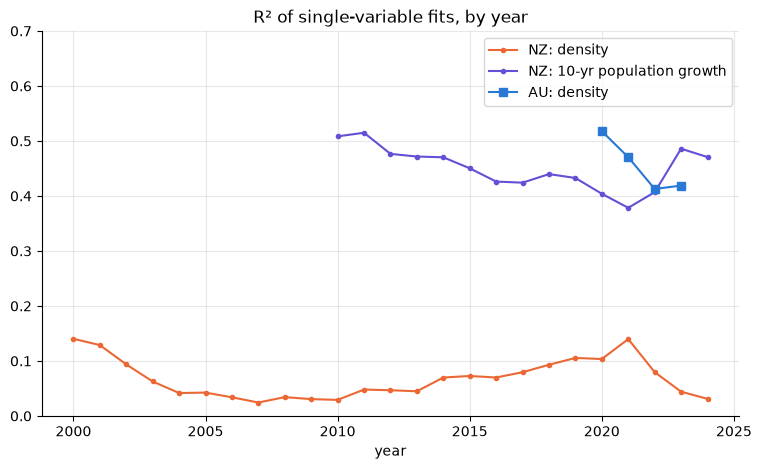

In [12]:
f_nz = pd.read_csv(TS/'nz_district_fits_2000_2024.csv', index_col=0); f_au = pd.read_csv(TS/'au_region_fits_2020_2023.csv', index_col=0)
ax = f_nz[['r2_density','r2_growth10']].plot(marker='o', ms=3, color=[NZ, '#6250d6'])
f_au.r2_density.plot(ax=ax, marker='s', color=AU, label='AU r2_density'); ax.legend(['NZ: density', 'NZ: 10-yr population growth', 'AU: density'])
ax.set_ylim(0, .7); ax.set_title('R² of single-variable fits, by year'); f_nz.round(3).tail(8)

In [13]:
panel = pd.read_csv(TS/'nz_district_effort_panel_2000_2024.csv')
wide = panel.pivot(index='ta', columns='year', values='eff')
chg = (wide[2024] - wide[2004]).sort_values()
print('Largest rises in effort, 2004 → 2024 (years of wage):'); print(chg.tail(10).round(1)); print('\nSmallest:'); print(chg.head(5).round(1))

Largest rises in effort, 2004 → 2024 (years of wage):
ta
Rangitikei               5.2
Opotiki                  5.2
Gisborne                 5.5
Western Bay of Plenty    5.7
Waipa                    6.1
Matamata-Piako           6.1
Queenstown-Lakes         6.3
South Wairarapa          6.4
Kaipara                  6.6
Waikato                  6.9
dtype: float64

Smallest:
ta
Kaikoura     -1.4
Tasman        1.3
Wellington    2.0
Nelson        2.1
Buller        2.2
dtype: float64


## 7. Maps
Matplotlib versions of the page's choropleths, drawn straight from the boundary files in `raw/geo` (ABS ASGS 2021 SA4, generalised; Stats NZ TALB 2023, clipped to the coastline, Auckland local boards dissolved). No GIS library needed: each ring becomes a polygon in a `PolyCollection`.

Australia is mapped at **SA4** level (88 regions), finer than the 50 labour-market regions used in the fits, so inner-city SA4s show up separately. SA4 wages are **by residence** (ATO), which is why effort inside Sydney peaks in the Eastern Suburbs rather than the CBD.

In [14]:
import json, re, unicodedata
from matplotlib.collections import PolyCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
import matplotlib as mpl

def rings(g):
    return g['coordinates'] if g['type'] == 'Polygon' else [r for p in g['coordinates'] for r in p]
def norm_ta(x):
    x = unicodedata.normalize('NFKD', str(x)).encode('ascii', 'ignore').decode()
    x = re.sub(r'\s+(District|City|Local Board Area|Local Board)$', '', x).strip()
    return {'Wanganui': 'Whanganui'}.get(x, x)
def ring_centroid(r):
    x = np.array([p[0] for p in r]); y = np.array([p[1] for p in r]); a = x*np.roll(y, -1) - np.roll(x, -1)*y; A = a.sum()/2
    return None if abs(A) < 1e-12 else (abs(A), ((x+np.roll(x, -1))*a).sum()/(6*A), ((y+np.roll(y, -1))*a).sum()/(6*A))
def centroid(rs):
    cs = [c for c in map(ring_centroid, rs) if c]; w = sum(c[0] for c in cs)
    return sum(c[0]*c[1] for c in cs)/w, sum(c[0]*c[2] for c in cs)/w
def km(lo1, la1, lo2, la2):
    p = np.pi/180; a = np.sin((la2-la1)*p/2)**2 + np.cos(la1*p)*np.cos(la2*p)*np.sin((lo2-lo1)*p/2)**2; return 12742*np.arcsin(np.sqrt(a))

# --- AU: SA4 geometry and SA4-level data
g = json.load(open(RAW/'geo'/'sa4_0.002.geojson'))
au_geo = {f['properties']['sa4_code_2021']: [r for r in rings(f['geometry']) if 112 < np.mean([p[0] for p in r]) < 154.2 and -44 < np.mean([p[1] for p in r]) < -9]
          for f in g['features'] if f['geometry']}
sa4 = pd.read_csv(RAW/'au'/'au_raw.csv', dtype={'sa4': str}).set_index('sa4')
sa4['price'] = (sa4.house_price*sa4.house_n + sa4.unit_price*sa4.unit_n) / (sa4.house_n + sa4.unit_n)
sa4['eff'] = sa4.price / sa4.wage; sa4['dens'] = sa4.workers_pow_2021 / sa4.area_km2
dbr = pd.read_csv(RAW/'au'/'dbr_sa4.csv', low_memory=False, dtype={'Code': str}); dbr = dbr[dbr.Code.str.fullmatch(r'\d{3}')]
J = 'Jobs in Australia - year ended 30 June :: Number of employee jobs - total'
jobs = dbr.assign(v=pd.to_numeric(dbr[J].astype(str).str.replace(',', ''), errors='coerce')).pivot_table(index='Code', columns='Year', values='v')
sa4['jobs_g'] = (jobs[2023]/jobs[2018] - 1)*100; nat_au_g = (jobs[2023].sum()/jobs[2018].sum() - 1)*100
for c, rs in au_geo.items():
    if c in sa4.index and rs: sa4.loc[c, ['lon', 'lat']] = centroid(rs)

# --- NZ: district geometry (Auckland local boards dissolved) and district-level data
t = json.load(open(RAW/'geo'/'talb.geojson')); nz_geo, land = {}, {}
for f in t['features']:
    p = f['properties']; ta = 'Auckland' if p['TALB2023_V1_00'].startswith('076') else norm_ta(p['TALB2023_V1_00_NAME_ASCII'])
    if ta in ('Chatham Islands', 'Area Outside Territorial Authority'): continue
    nz_geo.setdefault(ta, []).extend(rings(f['geometry'])); land[ta] = land.get(ta, 0) + p['LAND_AREA_SQ_KM']
ta_ = pd.read_csv(RAW/'nz'/'nz_raw.csv', index_col=0).drop(index=['Chatham Islands'])
ta_['eff'] = ta_.median_sale_price / ta_.wage; ta_['dens'] = ta_.employees / pd.Series(land)
bd = pd.read_csv(RAW/'nz'/'fnz_bd.csv'); bd = bd[(bd.Measure == 'Employee count') & (bd.Industry == 'Total all industries')]
emp = bd.assign(ta=bd['Territorial authority'].map(norm_ta)).pivot_table(index='ta', columns='Year as at February', values='Value', aggfunc='sum')
ta_['emp_g'] = (emp[2025]/emp[2016] - 1)*100; nat_nz_g = (emp.loc['New Zealand', 2025]/emp.loc['New Zealand', 2016] - 1)*100
nzw = pd.read_csv(TS/'nz_district_effort_panel_2000_2024.csv').pivot(index='ta', columns='year', values='eff')
ta_['eff_chg'] = nzw[2024] - nzw[2004]
for k, rs in nz_geo.items(): ta_.loc[k, ['lon', 'lat']] = centroid(rs)
print(f'{len(au_geo)} SA4 shapes, {len(nz_geo)} NZ districts; national job growth AU {nat_au_g:.1f}% (2018-23), NZ {nat_nz_g:.1f}% (2016-25)')

89 SA4 shapes, 67 NZ districts; national job growth AU 21.4% (2018-23), NZ 16.3% (2016-25)


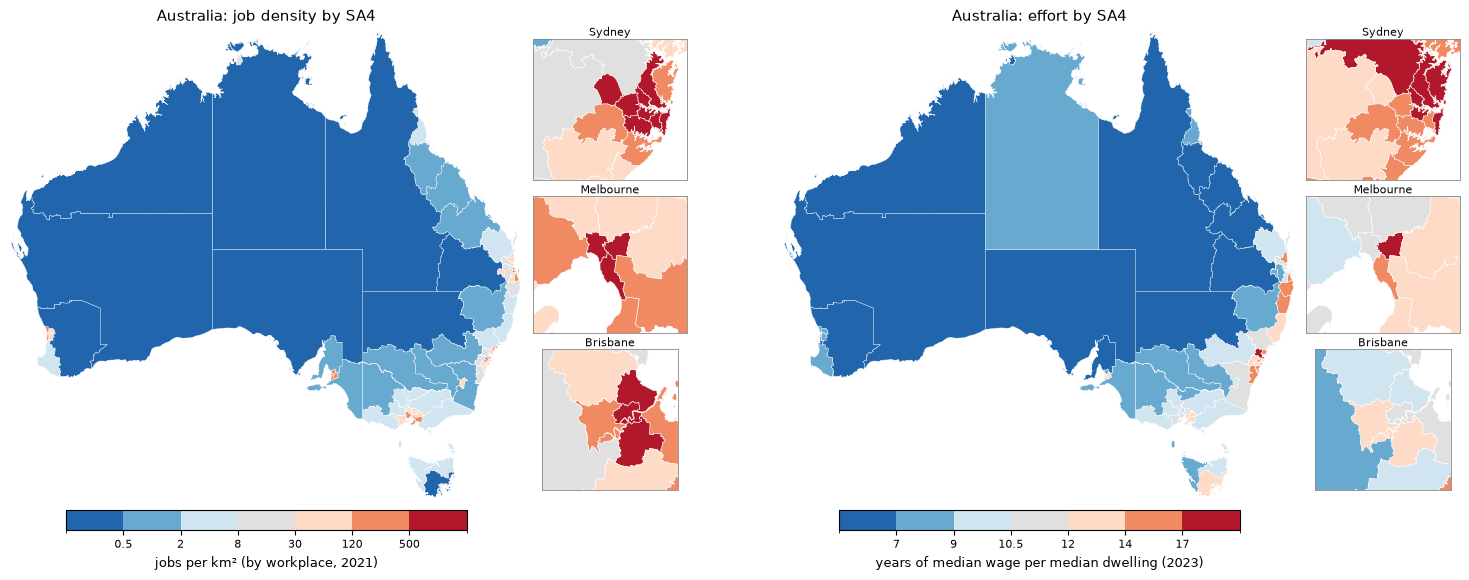

In [15]:
DIV = ['#2166ac', '#67a9cf', '#d1e5f0', '#e0e0e0', '#fddbc7', '#ef8a62', '#b2182b']   # blue = sparse/cheap, red = dense/dear
SEQ = ['#fff5eb', '#fdd0a2', '#fdae6b', '#fd8d3c', '#e6550d', '#a63603', '#7f2704']

def choropleth(ax, geo, values, breaks, colors=DIV, bbox=None, lw=.25):
    """geo: {key: [rings]}, values: Series keyed the same. bbox = (lon0, lat0, lon1, lat1) to zoom."""
    cmap, nrm = ListedColormap(colors), BoundaryNorm([-1e12] + list(breaks) + [1e12], len(colors))
    lat0 = np.mean([bbox[1], bbox[3]]) if bbox else np.mean([p[1] for rs in geo.values() for r in rs[:1] for p in r[:1]])
    k = np.cos(np.radians(lat0)); polys, cols = [], []
    for key, rs in geo.items():
        v = values.get(key, np.nan); c = '#f4f4f4' if pd.isna(v) else cmap(nrm(v))
        for r in rs:
            if bbox and not any(bbox[0]-.3 < p[0] < bbox[2]+.3 and bbox[1]-.3 < p[1] < bbox[3]+.3 for p in r): continue
            polys.append([(p[0]*k, p[1]) for p in r]); cols.append(c)
    ax.add_collection(PolyCollection(polys, facecolors=cols, edgecolors='white', linewidths=lw))
    if bbox: ax.set_xlim(bbox[0]*k, bbox[2]*k); ax.set_ylim(bbox[1], bbox[3])
    else: ax.autoscale_view()
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    return cmap, nrm

def legend_bar(fig, ax, cmap, nrm, breaks, label, fmt='{:g}'):
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=BoundaryNorm(range(len(breaks)+2), len(breaks)+1), cmap=cmap), ax=ax, orientation='horizontal', fraction=.04, pad=.02)
    cb.set_ticks(np.arange(1, len(breaks)+1)); cb.set_ticklabels([fmt.format(b) for b in breaks]); cb.set_label(label, fontsize=9); cb.ax.tick_params(labelsize=8)

def inset(ax, geo, values, breaks, bbox, title, pos, colors=DIV):
    a = ax.inset_axes(pos); choropleth(a, geo, values, breaks, colors, bbox=bbox, lw=.4)
    for s in a.spines.values(): s.set_visible(True); s.set_color('#888'); s.set_linewidth(.6)
    a.set_title(title, fontsize=8, pad=2)

AU_BOX = (112.8, -43.8, 153.8, -10.3)
SYD, MEL, BNE, PER = (150.35, -34.25, 151.4, -33.45), (144.55, -38.25, 145.55, -37.55), (152.65, -27.75, 153.25, -27.2), (115.65, -32.3, 116.15, -31.65)
EB, DB, GB = [7, 9, 10.5, 12, 14, 17], [0.5, 2, 8, 30, 120, 500], [-15, -7, -2, 2, 7, 15]

def au_insets(ax, vals, br, cl=DIV):   # inset column to the right of the map, so the coast stays visible
    for bb, nm, y in [(SYD, 'Sydney', .68), (MEL, 'Melbourne', .35), (BNE, 'Brisbane', .02)]: inset(ax, au_geo, vals, br, bb, nm, [1.02, y, .3, .3], cl)

def au_pair(cols, breaks, labels, fmts, titles, colors=(DIV, DIV)):
    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'wspace': .42})
    for ax, col, br, lab, fm, ti, cl in zip(axes, cols, breaks, labels, fmts, titles, colors):
        cm, nm = choropleth(ax, au_geo, sa4[col], br, cl, bbox=AU_BOX); ax.set_title(ti, fontsize=11)
        au_insets(ax, sa4[col], br, cl); legend_bar(fig, ax, cm, nm, br, lab, fm)

au_pair(['dens', 'eff'], [DB, EB], ['jobs per km² (by workplace, 2021)', 'years of median wage per median dwelling (2023)'], ['{:g}', '{:g}'],
        ['Australia: job density by SA4', 'Australia: effort by SA4'])

The two Australian maps line up along the east coast (Sydney to the Sunshine Coast) and in inner Melbourne; the interior and the mining regions are blue on both. That is the visual version of the R² 0.42 fit.

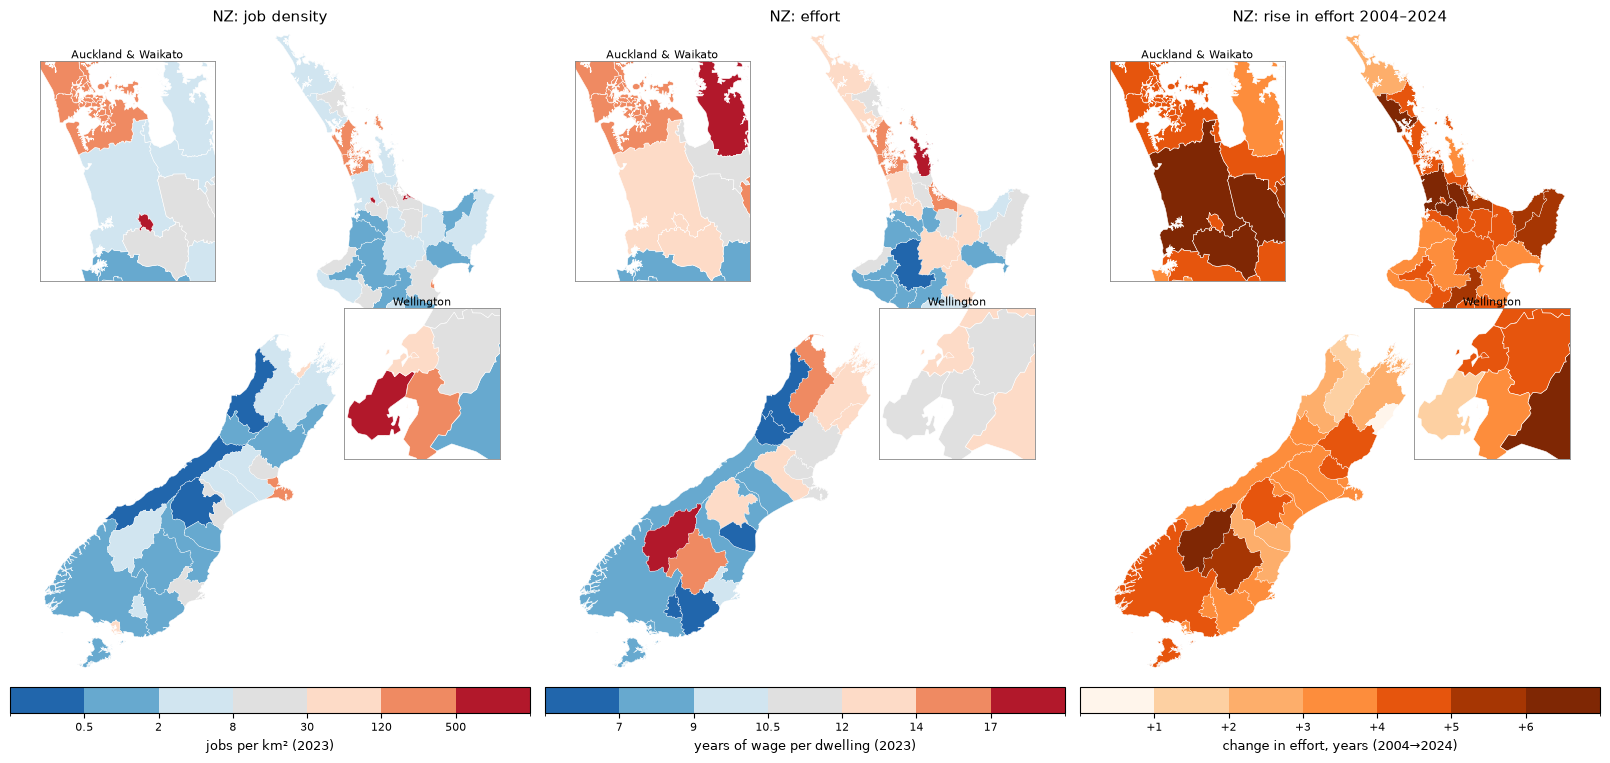

In [16]:
NZ_BOX = (166.3, -47.4, 178.7, -34.3); WLG, AKL = (174.6, -41.42, 175.25, -40.95), (174.3, -38.2, 175.9, -36.6)
def nz_trio(cols, breaks, labels, titles, colors, fmts):
    fig, axes = plt.subplots(1, len(cols), figsize=(5.4*len(cols), 7.5))
    for ax, col, br, lab, ti, cl, fm in zip(axes, cols, breaks, labels, titles, colors, fmts):
        cm, nm = choropleth(ax, nz_geo, ta_[col], br, cl, bbox=NZ_BOX); ax.set_title(ti, fontsize=11)
        inset(ax, nz_geo, ta_[col], br, AKL, 'Auckland & Waikato', [.0, .58, .38, .4], cl); inset(ax, nz_geo, ta_[col], br, WLG, 'Wellington', [.66, .3, .34, .3], cl)
        legend_bar(fig, ax, cm, nm, br, lab, fm)
    plt.tight_layout()
ta_['emp_rel'] = ta_.emp_g - nat_nz_g
nz_trio(['dens', 'eff', 'eff_chg'], [DB, EB, [1, 2, 3, 4, 5, 6]], ['jobs per km² (2023)', 'years of wage per dwelling (2023)', 'change in effort, years (2004→2024)'],
        ['NZ: job density', 'NZ: effort', 'NZ: rise in effort 2004–2024'], [DIV, DIV, SEQ], ['{:g}', '{:g}', '+{:g}'])

NZ density and effort do **not** line up: Coromandel, Queenstown, Tasman and Central Otago are as red as Auckland on effort without being dense. The third map shows where effort *rose*: a belt around Auckland and Hamilton, plus Queenstown and Central Otago.

AU fastest: [['Melbourne - West', 35.4], ['Ipswich', 33.9], ['Perth - North East', 33.5], ['Logan - Beaudesert', 33.4], ['Sydney - Blacktown', 32.4]]
NZ fastest: {'Queenstown-Lakes': 48.0, 'Selwyn': 38.2, 'Porirua': 37.4, 'Upper Hutt': 31.7, 'Waikato': 31.2}


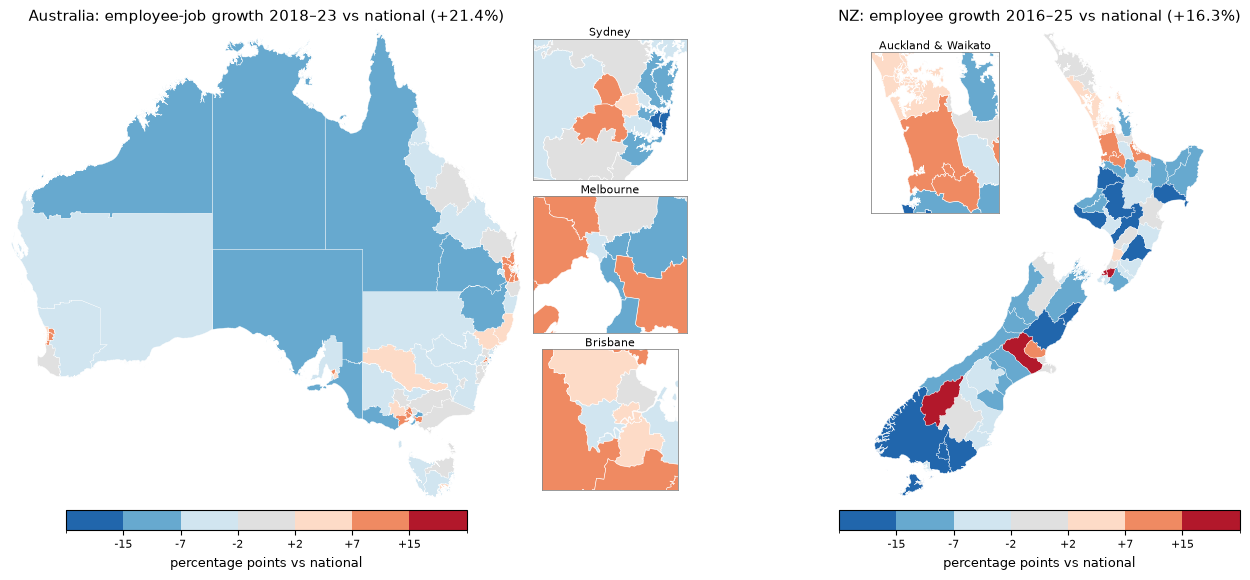

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'wspace': .42})
sa4['jobs_rel'] = sa4.jobs_g - nat_au_g
cm, nm = choropleth(axes[0], au_geo, sa4.jobs_rel, GB, bbox=AU_BOX); axes[0].set_title(f'Australia: employee-job growth 2018–23 vs national (+{nat_au_g:.1f}%)', fontsize=11)
au_insets(axes[0], sa4.jobs_rel, GB)
legend_bar(fig, axes[0], cm, nm, GB, 'percentage points vs national', '{:+g}')
cm, nm = choropleth(axes[1], nz_geo, ta_.emp_rel, GB, bbox=NZ_BOX); axes[1].set_title(f'NZ: employee growth 2016–25 vs national (+{nat_nz_g:.1f}%)', fontsize=11)
inset(axes[1], nz_geo, ta_.emp_rel, GB, AKL, 'Auckland & Waikato', [.0, .58, .38, .4])
legend_bar(fig, axes[1], cm, nm, GB, 'percentage points vs national', '{:+g}')
print('AU fastest:', sa4.nlargest(5, 'jobs_g')[['name', 'jobs_g']].round(1).values.tolist()); print('NZ fastest:', ta_.emp_g.nlargest(5).round(1).to_dict())

Caveat: the ABS *Jobs in Australia* series counts jobs by where the **worker lives**, so the AU growth map shows where workers settle (outer suburbs), not where jobs are created.

## 8. Exploration: where is housing dearer than density predicts?
Fit effort on ln(density) at the mapped level (AU SA4, NZ district), then map the residual. Red = dearer than its density implies (amenity, coast, tourism, supply limits); blue = cheaper.

,AU dearer than predicted,AU cheaper,NZ dearer,NZ cheaper
0,"(Sydney - Northern Beaches, 11.2)","(Perth - South West, -5.9)","(Queenstown-Lakes, 15.4)","(Kawerau, -5.9)"
1,"(Sydney - Eastern Suburbs, 10.8)","(Perth - South East, -5.2)","(Thames-Coromandel, 7.6)","(Grey, -4.6)"
2,"(Sydney - Baulkham Hills and Hawkesbury, 8.2)","(Melbourne - Inner, -5.0)","(Western Bay of Plenty, 5.8)","(Invercargill, -4.4)"
3,"(Sydney - North Sydney and Hornsby, 6.8)","(Perth - North West, -4.7)","(Tasman, 5.7)","(Buller, -4.3)"
4,"(Richmond - Tweed, 6.3)","(Mandurah, -4.6)","(Central Otago, 5.1)","(Gore, -4.1)"
5,"(Southern Highlands and Shoalhaven, 6.2)","(Perth - North East, -4.5)","(Auckland, 3.3)","(South Waikato, -3.8)"
6,"(Melbourne - Inner East, 4.5)","(Brisbane Inner City, -4.4)","(Taupo, 2.9)","(Clutha, -3.7)"
7,"(Coffs Harbour - Grafton, 4.4)","(Darwin, -4.3)","(South Wairarapa, 2.7)","(South Taranaki, -3.6)"


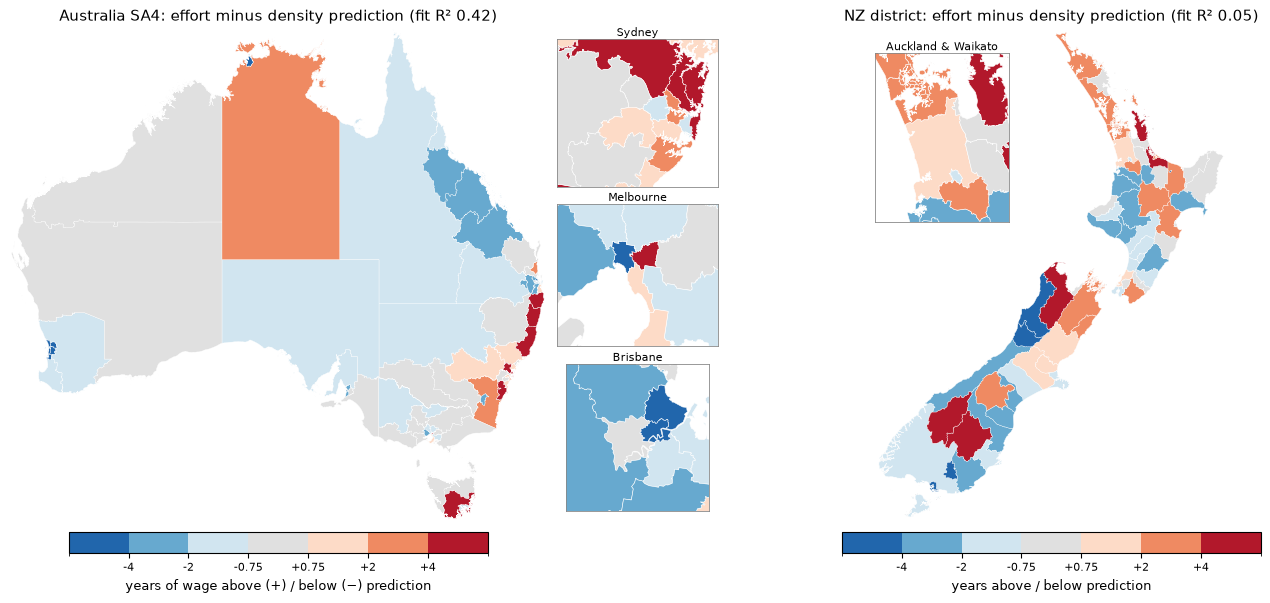

In [18]:
def resid(df, x='dens', y='eff'):
    d = df.dropna(subset=[x, y]); b, r2, res = ols([np.log(d[x].values)], d[y].values); return pd.Series(res, d.index), r2
ra, r2a = resid(sa4); rn, r2n = resid(ta_)
RB = [-4, -2, -0.75, 0.75, 2, 4]
fig, axes = plt.subplots(1, 2, figsize=(17, 6.8), gridspec_kw={'wspace': .42})
cm, nm = choropleth(axes[0], au_geo, ra, RB, bbox=AU_BOX); axes[0].set_title(f'Australia SA4: effort minus density prediction (fit R² {r2a:.2f})', fontsize=11)
au_insets(axes[0], ra, RB)
legend_bar(fig, axes[0], cm, nm, RB, 'years of wage above (+) / below (−) prediction', '{:+g}')
cm, nm = choropleth(axes[1], nz_geo, rn, RB, bbox=NZ_BOX); axes[1].set_title(f'NZ district: effort minus density prediction (fit R² {r2n:.2f})', fontsize=11)
inset(axes[1], nz_geo, rn, RB, AKL, 'Auckland & Waikato', [.0, .58, .38, .4]); legend_bar(fig, axes[1], cm, nm, RB, 'years above / below prediction', '{:+g}')
pd.DataFrame({'AU dearer than predicted': ra.nlargest(8).rename(sa4.name).round(1).items(), 'AU cheaper': ra.nsmallest(8).rename(sa4.name).round(1).items(),
              'NZ dearer': rn.nlargest(8).round(1).items(), 'NZ cheaper': rn.nsmallest(8).round(1).items()})

* **Australia, dearer than density predicts:** Sydney's Northern Beaches (+11.2 years) and Eastern Suburbs (+10.8), the Hills, the NSW North Coast (Richmond–Tweed, Coffs Harbour) and the Southern Highlands. The common factors are coast, amenity and high residential incomes.
* **Australia, cheaper:** all of suburban Perth, inner Melbourne and inner Brisbane (dense job centres with plenty of apartments), and Darwin.
* **NZ, dearer:** Queenstown (+15.4), Coromandel, Western Bay of Plenty, Tasman and Central Otago. These are lifestyle and retirement districts, not job centres. **NZ, cheaper:** Kawerau, Grey, Invercargill, Buller and Gore, which are small industrial or mining towns.

The AU residual map is close to a map of the coast. That suggests the "tourism" variable in the AU two-variable model is partly measuring coastal amenity.

## 9. Exploration: the bid-rent curve — does effort fall with distance from the CBD?
Classic urban economics says land is dearest at the centre. Each point is an SA4 within 200 km of its state capital's CBD (distance from the SA4's area-weighted centroid, so large outer SA4s sit further out than their populated edge).

,SA4s,effort change per 10 km,"corr(effort, km)","corr(ln price, km)","corr(ln wage, km)",peak SA4,peak km
Sydney,19,-0.490644,-0.540433,-0.623166,-0.544288,Sydney - Eastern Suburbs,6.52861
Melbourne,14,-0.32014,-0.652357,-0.798362,-0.89237,Melbourne - Inner East,12.52269
Brisbane,12,0.048502,0.074728,-0.391733,-0.880284,Sunshine Coast,98.554178
Adelaide,6,-0.276845,-0.80767,-0.894726,-0.962438,Adelaide - Central and Hills,22.139464
Perth,7,-0.197275,-0.578451,-0.796627,-0.981562,Perth - Inner,4.789111


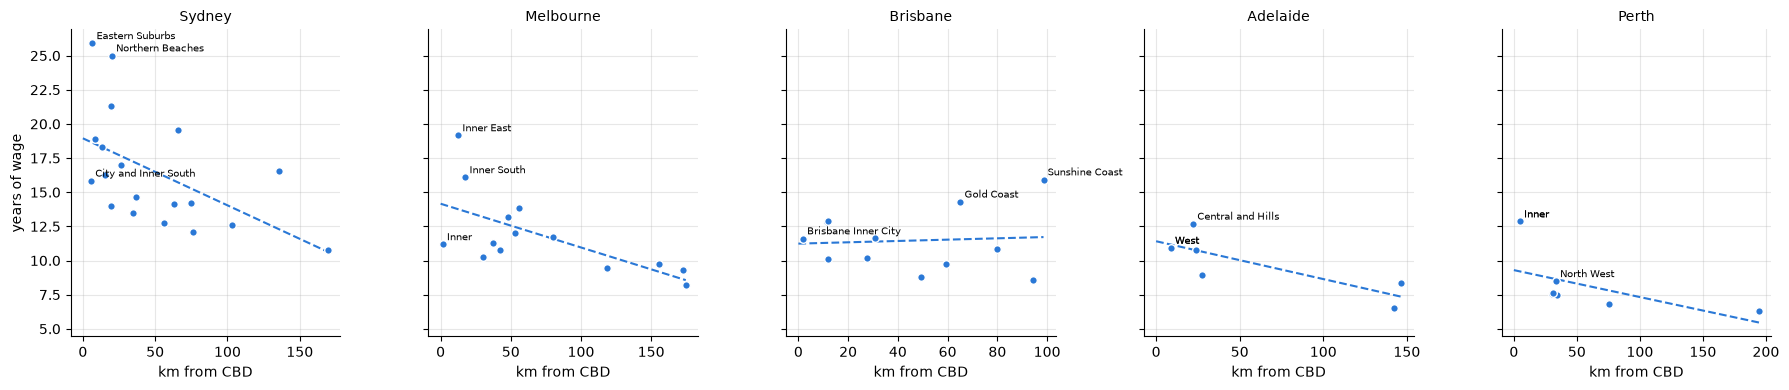

In [19]:
CBD = {'NSW': ('Sydney', 151.207, -33.868), 'VIC': ('Melbourne', 144.963, -37.814), 'QLD': ('Brisbane', 153.026, -27.469), 'SA': ('Adelaide', 138.600, -34.929), 'WA': ('Perth', 115.860, -31.952)}
sa4['km_cbd'] = [km(CBD[s][1], CBD[s][2], lo, la) if s in CBD else np.nan for s, lo, la in zip(sa4.state, sa4.lon, sa4.lat)]
near = sa4[sa4.km_cbd < 200]
fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharey=True); rows = {}
for ax, (st, (city, *_)) in zip(axes, CBD.items()):
    d = near[near.state == st]; b = np.polyfit(d.km_cbd, d.eff, 1)
    ax.scatter(d.km_cbd, d.eff, color=AU, s=30, edgecolor='white', zorder=3); xs = np.array([0, d.km_cbd.max()]); ax.plot(xs, b[0]*xs + b[1], '--', color=AU)
    for n in d.nlargest(2, 'eff').index.tolist() + d.nsmallest(1, 'km_cbd').index.tolist():
        ax.annotate(d.name[n].replace(city+' - ', '').replace('Sydney - ', ''), (d.km_cbd[n], d.eff[n]), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.set_title(city, fontsize=10); ax.set_xlabel('km from CBD')
    rows[city] = {'SA4s': len(d), 'effort change per 10 km': b[0]*10, 'corr(effort, km)': np.corrcoef(d.km_cbd, d.eff)[0, 1],
                  'corr(ln price, km)': np.corrcoef(d.km_cbd, np.log(d.price))[0, 1], 'corr(ln wage, km)': np.corrcoef(d.km_cbd, np.log(d.wage))[0, 1],
                  'peak SA4': d.name[d.eff.idxmax()], 'peak km': d.km_cbd[d.eff.idxmax()]}
axes[0].set_ylabel('years of wage'); plt.tight_layout(); pd.DataFrame(rows).T.round(2)

What to look for: prices fall with distance everywhere, but so do wages (measured by residence), so effort falls more gently than price.
* **Sydney** loses about 0.5 years of wage per 10 km, but the peak is not the CBD SA4 (15.8 years). It is the Eastern Suburbs (25.9) and the Northern Beaches (25.0, about 20 km out): coast and amenity beat proximity.
* **Brisbane** has no gradient (corr ≈ 0.07). The Sunshine Coast (15.9) and Gold Coast (14.3), 60–100 km out, are dearer than inner Brisbane (11.6). This is the Australian version of NZ's lifestyle-district pattern.
* **Perth** and **Adelaide** follow the textbook curve most closely, with wages falling almost in step with prices.

## 10. Exploration: have NZ districts converged?
Two standard tests from growth economics, applied to the 2000–2024 district panel:
* **β-convergence**: did districts that started cheap see effort rise faster?
* **σ-convergence**: is the spread (coefficient of variation) across districts shrinking?
And a spatial one: is effort rising fastest *near* Auckland (spillover from the main labour market)?

Spearman rank corr of effort 2004 vs 2024: 0.92
CV: {2000: 0.37, 2004: 0.51, 2008: 0.34, 2016: 0.45, 2021: 0.33, 2024: 0.31}
           median  count
km_akl                  
<50 km   4.792270      1
50–150   5.388583      8
150–300  4.345373     14
300–600  3.933614     24
600+     3.404545     19


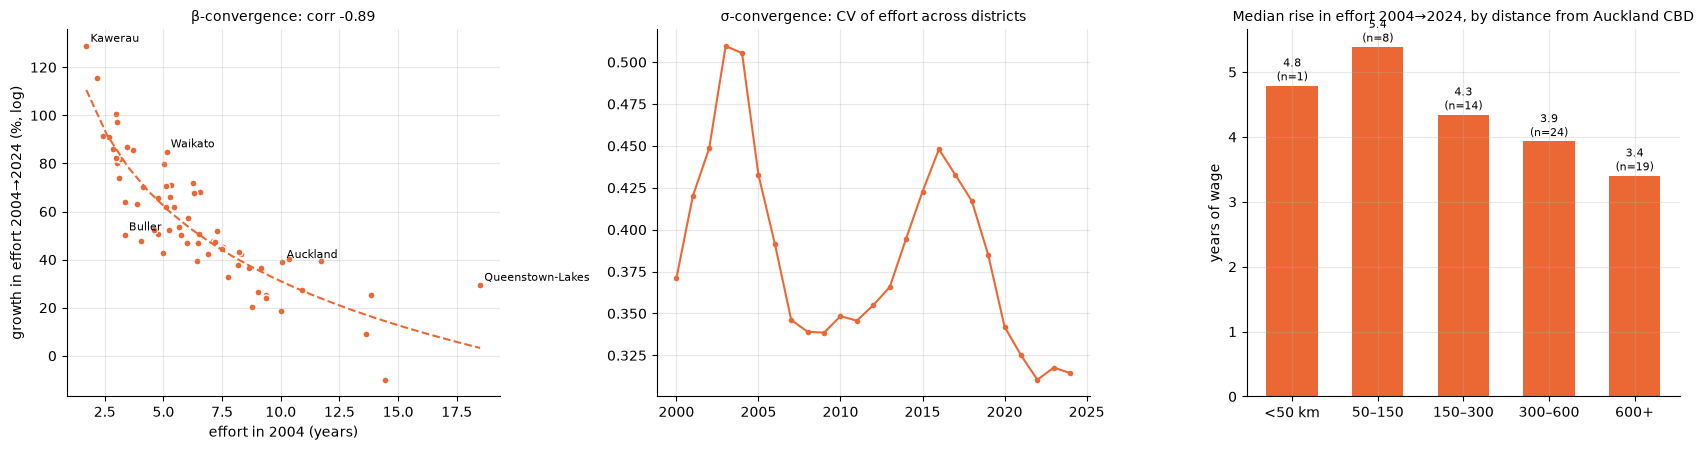

In [20]:
cv = nzw.std() / nzw.mean(); g = np.log(nzw[2024] / nzw[2004]); b = np.polyfit(np.log(nzw[2004]), g, 1)
ta_['km_akl'] = [km(174.763, -36.848, lo, la) for lo, la in zip(ta_.lon, ta_.lat)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].scatter(nzw[2004], g*100, color=NZ, s=26, edgecolor='white'); xs = np.linspace(nzw[2004].min(), nzw[2004].max(), 20); axes[0].plot(xs, (b[0]*np.log(xs) + b[1])*100, '--', color=NZ)
for n in ['Queenstown-Lakes', 'Auckland', 'Kawerau', 'Waikato', 'Buller']:
    if n in nzw.index: axes[0].annotate(n, (nzw.at[n, 2004], g[n]*100), fontsize=8, xytext=(3, 3), textcoords='offset points')
axes[0].set_xlabel('effort in 2004 (years)'); axes[0].set_ylabel('growth in effort 2004→2024 (%, log)'); axes[0].set_title(f'β-convergence: corr {np.corrcoef(np.log(nzw[2004]), g)[0, 1]:.2f}', fontsize=10)
cv.plot(ax=axes[1], color=NZ, marker='o', ms=3); axes[1].set_title('σ-convergence: CV of effort across districts', fontsize=10); axes[1].set_xlabel('')
d = ta_.dropna(subset=['eff_chg', 'km_akl']); bands = pd.cut(d.km_akl, [0, 50, 150, 300, 600, 1200], labels=['<50 km', '50–150', '150–300', '300–600', '600+'])
s = d.groupby(bands, observed=True).eff_chg.agg(['median', 'count']); axes[2].bar(s.index.astype(str), s['median'], color=NZ, width=.6)
for i, (m, c) in enumerate(zip(s['median'], s['count'])): axes[2].text(i, m + .08, f'{m:.1f}\n(n={c})', ha='center', fontsize=8)
axes[2].set_title('Median rise in effort 2004→2024, by distance from Auckland CBD', fontsize=10); axes[2].set_ylabel('years of wage'); plt.tight_layout()
print('Spearman rank corr of effort 2004 vs 2024:', round(nzw[2004].rank().corr(nzw[2024].rank()), 2))
print('CV:', cv.loc[[2000, 2004, 2008, 2016, 2021, 2024]].round(2).to_dict()); print(s)

* **β-convergence: strong.** Districts that started cheap saw the largest percentage rises (corr ≈ −0.89 between the 2004 level and 2004→24 log growth).
* **σ-convergence: since 2016.** The spread across districts fell from 0.45 to 0.31 (CV). But ratios converging still means dollar gaps widened.
* **The ranking barely moved.** The rank correlation between 2004 and 2024 is 0.92. Queenstown, Coromandel and Tauranga/Western Bay were at the top then and are now.
* **An Auckland halo.** Districts 50–150 km from Auckland's CBD rose most (median +5.4 years; Waikato +6.9, Kaipara +6.6, Waipa and Matamata-Piako +6.1). Districts more than 600 km away rose least (+3.4). This fits buyers priced out of Auckland moving into the commuter belt, but it is a correlation, not a test of migration.

## 11. Exploration: the repayment burden with the interest rates people actually faced (Australia)
Section 4 holds the rate at 4%. Here each year uses the **RBA standard variable owner-occupier rate** (table F5, annual average) and that year's capital-city effort from section 5 (median house ÷ average earnings).
The measure: the monthly repayment on a **30-year loan for 80% of the median house**, as a share of **two average earners' gross pay**. This is a standard affordability measure, used here because the original's never-repay rule (90% LTV, 45% of net pay) puts Sydney at "never" in almost every year since 1986 at the rates of the day, which tells you little.
From about 2004 most borrowers paid less than the standard rate, so the dashed lines use the RBA *discounted* variable rate where it exists.
NZ is not shown: the RBNZ mortgage-rate tables (B20/B3) block scripted downloads. Save `hb20.xlsx` from rbnz.govt.nz into `raw/rates/` to extend this.

,SVR %,discounted %,Sydney effort,Sydney burden %,Melbourne burden %,Brisbane burden %,Perth burden %,Sydney burden at discounted %
1986,15.0,NaN,5.5,33.1,27.4,24.1,25.2,NaN
1989,16.5,NaN,8.0,52.8,35.9,30.4,36.4,NaN
1995,10.5,NaN,7.2,31.9,18.8,23.6,21.4,NaN
2000,7.7,NaN,8.5,29.2,20.4,16.0,18.0,NaN
2008,8.9,8.3,10.1,38.9,33.9,34.0,33.9,36.7
2016,5.4,4.6,14.6,39.4,29.0,23.1,20.3,36.1
2021,4.5,3.5,17.5,42.7,31.3,24.1,17.6,38.0
2023,8.3,6.8,18.2,66.0,42.4,39.3,27.6,57.1
2025,8.3,6.4,18.1,65.6,39.7,46.3,37.0,54.3


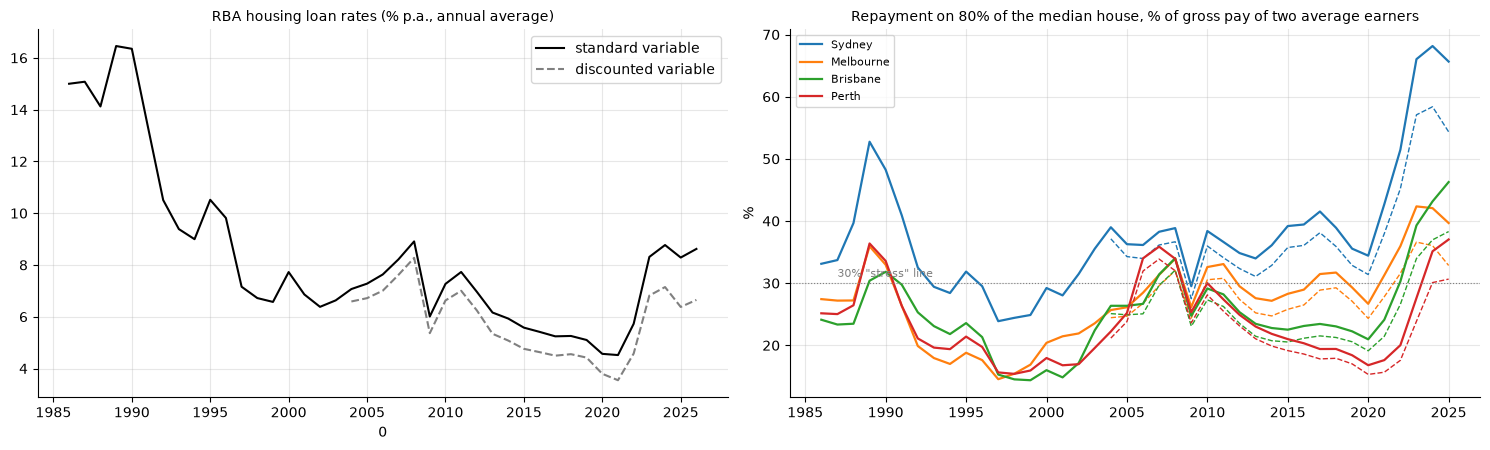

In [21]:
f5 = pd.read_excel(RAW/'rates'/'rba_f05hist.xlsx', header=None, skiprows=11).set_index(0)
svr = f5[3].astype(float).groupby(f5.index.year).mean().rename('standard variable'); disc = f5[4].astype(float).groupby(f5.index.year).mean().rename('discounted variable')
rates = pd.concat([svr, disc], axis=1).loc[1986:]

def burden(effort, rate, lvr=0.8, years=30, earners=2):
    """Annual repayment as a share of household gross pay. effort is in years of one earner's pay."""
    r, n = rate/12, years*12
    return lvr * effort * r / (1 - (1 + r)**-n) * 12 / earners

caps4 = ['Sydney', 'Melbourne', 'Brisbane', 'Perth']
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
rates.plot(ax=axes[0], color=['k', 'grey'], style=['-', '--']); axes[0].set_title('RBA housing loan rates (% p.a., annual average)', fontsize=10)
B = pd.DataFrame({c: [burden(au_ts.at[y, c], rates.at[y, 'standard variable']/100) for y in rates.index if y in au_ts.index] for c in caps4},
                 index=[y for y in rates.index if y in au_ts.index])
Bd = pd.DataFrame({c: [burden(au_ts.at[y, c], rates.at[y, 'discounted variable']/100) for y in B.index] for c in caps4}, index=B.index)
for c in caps4:
    l, = axes[1].plot(B.index, B[c]*100, lw=1.6, label=c); axes[1].plot(Bd.index, Bd[c]*100, '--', lw=1, color=l.get_color())
axes[1].axhline(30, color='grey', lw=.8, ls=':'); axes[1].text(1987, 31, '30% "stress" line', fontsize=8, color='grey')
axes[1].set_title('Repayment on 80% of the median house, % of gross pay of two average earners', fontsize=10); axes[1].legend(fontsize=8); axes[1].set_ylabel('%')
plt.tight_layout()
yrs = [y for y in [1986, 1989, 1995, 2000, 2008, 2016, 2021, 2023, 2025] if y in B.index]
pd.concat({'SVR %': rates.loc[yrs, 'standard variable'], 'discounted %': rates.loc[yrs, 'discounted variable'], 'Sydney effort': au_ts.loc[yrs, 'Sydney'],
           **{f'{c} burden %': B.loc[yrs, c]*100 for c in caps4}, 'Sydney burden at discounted %': Bd.loc[yrs, 'Sydney']*100}, axis=1).round(1)

**Reading it.**
* At the standard variable rate, a Sydney household needed about **66% of two average earners' gross pay** in 2023–25, against **53% at the 1989 peak**, when rates were 16.5%. At the discounted rate most borrowers actually got, it was 54–57%: still above 1989.
* The 2021 low in rates (4.5%) hid an effort ratio more than twice the 1989 level. Once rates went back above 8%, the high price level and the high rate arrived together.
* **Brisbane** is at a record (46% in 2025, against 30% in 1989). **Perth** (37%) is level with its 1989 and 2008 peaks. **Melbourne** (40%) is just below its 2023–24 high and above 1989 (36%).
* Caveats: average earnings, not household income. No allowance for the second earner's lower pay, tax changes, or the smaller deposits common in the 1980s. Before 1995 earnings follow the OECD income index (section 5).

## 12. Open questions
* **Supply.** Add dwelling stock or building consents per worker (ABS building approvals by SA2; Stats NZ consents by TA) to test the mechanism instead of density as a proxy.
* **Dwelling mix.** Control for the house/unit share (AU) or floor area (NZ consents give new-build floor area) to separate composition from price.
* **NZ interest rates.** Section 12 does AU only; RBNZ table B20 (blocked to scripts) would extend it to NZ.
* **Workplace vs residence.** Australian wages are by residence (ATO). The Census WPP has income by place of work in bands, which could replace them.
* **Longer AU regional history.** ABS Data by Region only has regional prices from 2020; state Valuer-General sales files (NSW from 1990, Vic) could extend this.

In [22]:
# Rebuild everything from raw/ (outputs written next to the inputs):
# uv run --with pandas --with openpyxl --with numpy python scripts/timeseries.py raw
# build_au.py / build_nz.py / analyse.py / robust.py take the same directory argument (they expect raw/au, raw/nz, raw/ts).